# ECG arrhythmia classification and PermFIT explainability: walkthrough

This notebook holds **all the code of the case study in one place**, in the order it is needed, with its
output under each cell:

| Section | Code from | Question |
|---|---|---|
| 0 Data | `ecg_utils.py` | What does one row of data look like? |
| 1 | `task1.py` | What do the 8 beat classes look like, and how many are there? |
| 2 | `task2_svm.py` | How well does an SVM classify beats it has not seen? |
| 3 | `task3.py` | ...and beats of **patients** it has not seen? |
| 4 | `ecg_utils.py`, `task4_permfit.py` | Which part of the heartbeat does the SVM rely on? (PermFIT) |
| 5 | `tune_hyperparameters.py`, `ecg_utils.py`, `task5_compare_classifiers.py` | Does a Random Forest rely on the same parts? |

The code cells are copied from the `.py` files, which `run_all.sh` runs, so both give the same numbers.
Tasks 1–3 are the team members' code as written; small fixes are marked `# FIX`.

**Before running:**
1. Use the Python environment from `requirements.txt` as the kernel (in VS Code: *Select Kernel*, top right).
2. Put the 48 raw MIT-BIH records in `mitbih/` (see `README.md`). If `data/` does not exist yet, the first
   code cell builds it by running `00_preprocess.ipynb` and `01_split_resample.ipynb` (once, about 1 minute).

With `RUN_PERMFIT = False` the notebook loads the saved PermFIT results from `results/` and runs in a few
minutes. With `True` it recomputes them (about 1.5 hours).

In [1]:
# Setup check: right folder, right Python environment, data present
import importlib.util, subprocess, sys
from pathlib import Path

if not Path("00_preprocess.ipynb").exists():
    raise RuntimeError("Run this notebook from the Final_Submission folder.")
missing = [m for m in ("numpy", "pandas", "sklearn", "matplotlib", "wfdb", "biosppy") if importlib.util.find_spec(m) is None]
if missing:
    raise ModuleNotFoundError(f"Missing packages {missing} in the Python at {sys.executable}. Select the project's "
                              "environment as the kernel, or run:  pip install -r requirements.txt")
DATA_FILES = ["all_data.csv", "train_beats.csv", "test_beats.csv", "train_patients.csv", "test_patients.csv"]
if not all((Path("data") / f).exists() for f in DATA_FILES):
    if not any(Path("mitbih").glob("*.dat")):
        raise FileNotFoundError("data/ is missing and there are no raw MIT-BIH files in mitbih/ to build it from. "
                                "Download them from https://physionet.org/content/mitdb/1.0.0/ (see README.md).")
    for nb in ("00_preprocess.ipynb", "01_split_resample.ipynb"):
        print("Building data/ - running", nb, "...", flush=True)
        subprocess.run([sys.executable, "-m", "jupyter", "nbconvert", "--to", "notebook", "--execute", "--inplace", nb], check=True)
print("Setup OK")

Setup OK


In [2]:
RUN_PERMFIT = False   # True = recompute PermFIT (about 1.5 h); False = load the saved results from results/

## 0. The data

Each row of a CSV file is one heartbeat:

| columns | content |
|---|---|
| 0 – 274 | 275 standardised samples (0.76 s at 360 Hz), R-peak at sample 137 |
| 275 | class ID 1–8 = N, L, R, V, A, F, f, / |
| 276 | record (patient) number |

Two validation protocols:
- **Beat hold-out**: a random 75 / 25 split of all beats. Beats of the same patient are in both sets.
- **Patient hold-out**: records 104, 113, 119, 208 and 210 are kept out of training completely.

The training sets are re-sampled so that every class has the same number of beats.

Imports, paths, constants and the data loader from `ecg_utils.py` (shared by Tasks 4 and 5):

In [3]:
%matplotlib inline
import pandas as pd
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, precision_recall_fscore_support, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

DATA_DIR = Path("data")
FIG_DIR = Path("figures")
RESULTS_DIR = Path("results")
FIG_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

SEED = 42
CLASS_IDS = [1, 2, 3, 4, 5, 6, 7, 8]
CLASS_NAMES = ["N", "L", "R", "V", "A", "F", "f", "/"]
SPLITS = {"beats": "beat hold-out", "patients": "patient hold-out"}

# each beat (275 samples) is cut into 11 slices of 25 samples
N_SLICES = 11
SLICE_LENGTH = 25
SLICE_REGIONS = [("PR interval", 1, 4), ("QRS complex", 5, 7), ("ST segment / T-wave", 8, 11)]


def load_split(name):
    # name = "beats" or "patients"; column 275 is the label, column 276 the record number
    train = np.loadtxt(DATA_DIR / f"train_{name}.csv", delimiter=",")
    test = np.loadtxt(DATA_DIR / f"test_{name}.csv", delimiter=",")
    return train[:, :275], train[:, 275].astype(int), test[:, :275], test[:, 275].astype(int)

In [4]:
# Beats per class in each set
counts = []
for split, name in SPLITS.items():
    _, y_train, _, y_test = load_split(split)
    for part, y in (("train", y_train), ("test", y_test)):
        counts.append(pd.Series(np.bincount(y, minlength=9)[1:], index=CLASS_NAMES, name=f"{name} - {part}"))
pd.DataFrame(counts)

,N,L,R,V,A,F,f,/
beat hold-out - train,3874,3874,3874,3874,3874,3874,3874,3874
beat hold-out - test,28474,1636,2581,1307,783,191,416,2054
patient hold-out - train,4423,4423,4423,4423,4423,4423,4423,4423
patient hold-out - test,9363,0,0,1087,0,387,1138,2507


Training sets are balanced; test sets keep the real class mix. The patient test set has **no L, R or A
beats**, so its macro scores can only average the classes that are present.

## 1. Task 1: look at the data
*Code: `task1.py` (team member).*

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd


# FIX: read from the shared data/ folder (run from the Final_Submission folder)
alldata = pd.read_csv('data/all_data.csv', header=None).to_numpy()
print('Data shape:', alldata.shape)
print('First five rows:')
print(alldata[:5])

Data shape: (149768, 277)
First five rows:
[[ 1.080076e+00  1.080076e+00  1.080076e+00 ... -2.369180e-01
   1.000000e+00  1.000000e+02]
 [ 1.619185e+00  1.451040e-01  1.968260e-01 ...  6.752100e-02
   1.000000e+00  1.000000e+02]
 [ 1.878227e+00  9.147700e-02  6.394000e-03 ...  1.198390e-01
   1.000000e+00  1.000000e+02]
 [ 1.997797e+00 -3.058800e-02 -7.590000e-04 ...  2.080450e-01
   1.000000e+00  1.000000e+02]
 [ 2.129467e+00  1.732490e-01  4.704100e-02 ...  3.310080e-01
   1.000000e+00  1.000000e+02]]


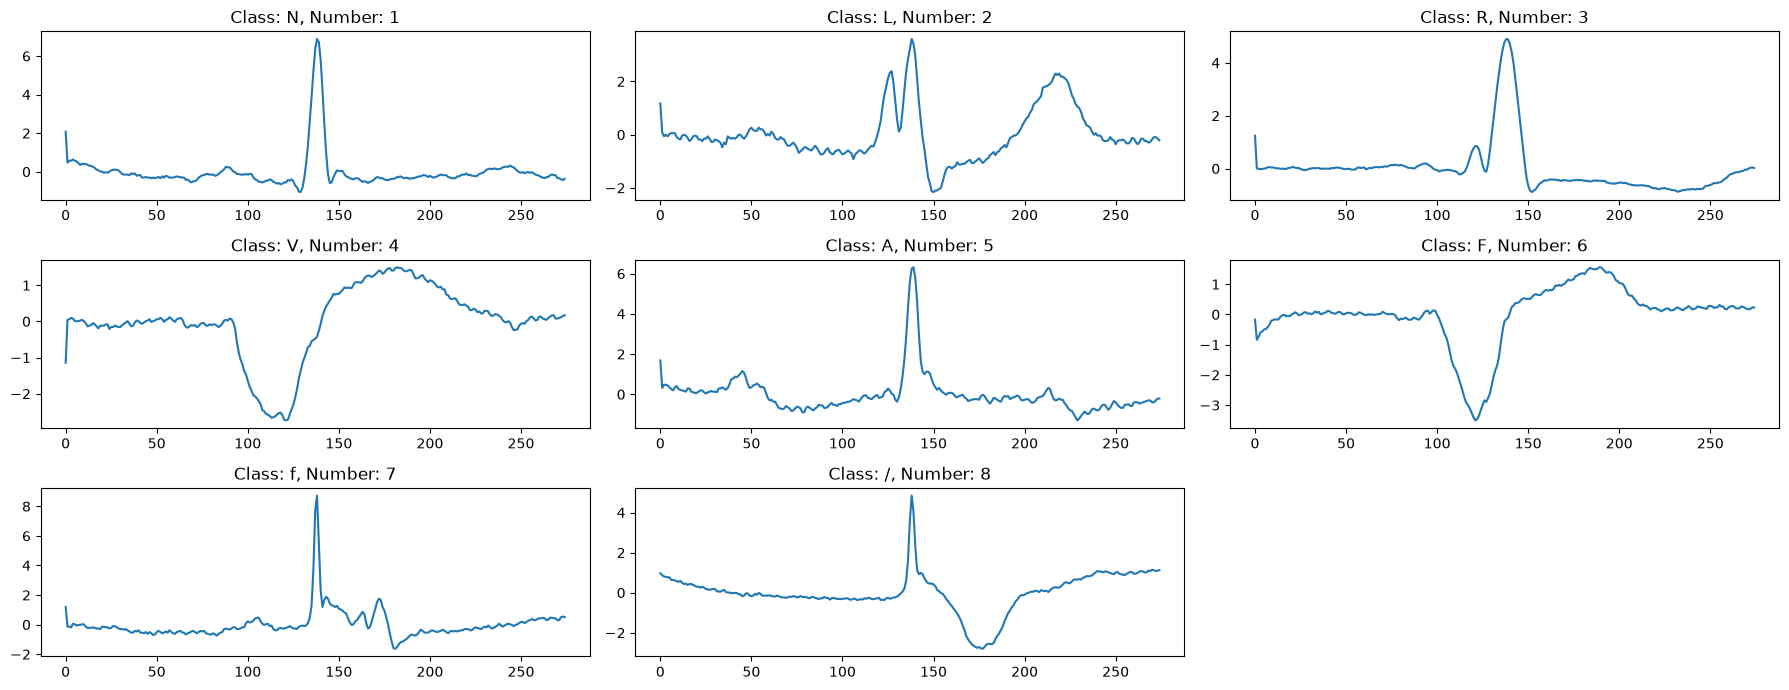

In [6]:
fig, ax = plt.subplots(3, 3, figsize=(18, 7))
categories = ['N', 'L', 'R', 'V', 'A', 'F', 'f', '/']
#"N": Normal beat
#"L": Left bundle branch block beat
#"R": Right bundle branch block beat
#"V": Premature ventricular contraction
#"A": Atrial premature beat
#"F": Fusion of ventricular and normal beat
#"f": Fusion of paced and normal beat
#"/": Paced beat

for i in range(len(categories)):
    indices_category = np.argwhere(alldata[:, -2] == i + 1)
    if len(indices_category) > 0:
        # FIX: plot a beat from the middle of the class; the first beat of a class sits at the
        # start of a recording and is partly zero-padded (flat line at the start)
        ax[i // 3, i % 3].plot(np.arange(275), alldata[indices_category[len(indices_category) // 2], :-2][0])
    ax[i // 3, i % 3].set_title('Class: ' + categories[i] + ', Number: ' + str(i + 1))

ax[2, 2].axis('off')
plt.tight_layout()
fig.savefig('figures/task1_ecg_beats.jpg', dpi=400)  # FIX: save into figures/
plt.show()

Class N : 113682
Class L : 6568
Class R : 10471
Class V : 5251
Class A : 3127
Class F : 813
Class f : 1627
Class / : 8229


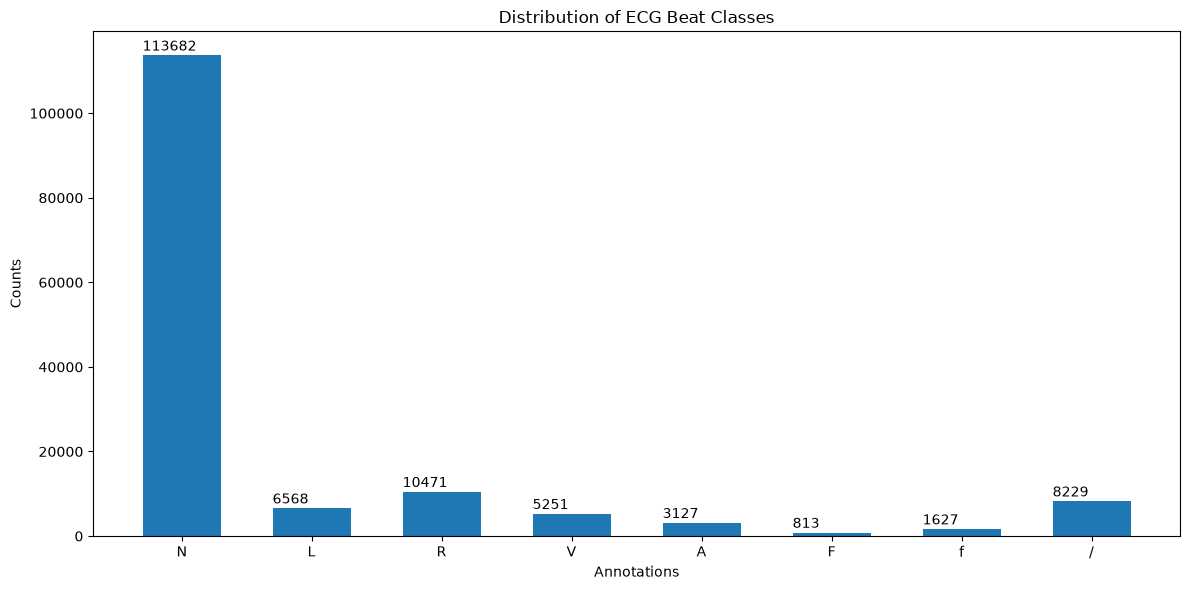

In [7]:
# 3. Count and plot the distribution of the eight classes.
counts = []
for i in range(len(categories)):
    count = np.sum(alldata[:, -2] == i + 1)
    counts.append(count)
    print('Class', categories[i], ':', count)

fig = plt.figure(figsize=(12, 6))
barplt = plt.bar(categories, counts, width=0.6)
plt.title('Distribution of ECG Beat Classes')
plt.xlabel('Annotations')
plt.ylabel('Counts')

for bar in barplt:
    yval = bar.get_height()
    plt.text(bar.get_x(), yval + max(counts) * 0.01, str(int(yval)))

plt.tight_layout()
fig.savefig('figures/task1_class_distribution.jpg', dpi=400)  # FIX: save into figures/
plt.show()

N beats are about 76% of all beats. That is why the training sets are re-sampled, and why we report
**macro** precision, recall and F1: every class counts equally, instead of N dominating the score.

## 2. Task 2: SVM, beat hold-out
*Code: `task2_svm.py` (team member).*

An **SVM** (support vector machine) with an RBF kernel compares a new beat with stored "support" beats
from the training set and separates the classes with a smooth boundary. `C = 1` (default) controls how
strictly it fits the training beats.

In [8]:
import numpy as np
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix
)

# read beat holdout data
# FIX: read from the shared data/ folder (run from the Final_Submission folder)
train = np.loadtxt("./data/train_beats.csv", delimiter=",")
test = np.loadtxt("./data/test_beats.csv", delimiter=",")

X_train, y_train = train[:, :275], train[:, 275].astype(int)
X_test, y_test = test[:, :275], test[:, 275].astype(int)

In [9]:
def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)
    labels = [1, 2, 3, 4, 5, 6, 7, 8]

    results = {
        "accuracy": accuracy_score(y_test, y_pred),
        "precision_macro": precision_score(
            y_test, y_pred, labels=labels, average="macro", zero_division=0
        ),
        "recall_macro": recall_score(
            y_test, y_pred, labels=labels, average="macro", zero_division=0
        ),
        "f1_macro": f1_score(
            y_test, y_pred, labels=labels, average="macro", zero_division=0
        ),
        "confusion_matrix": confusion_matrix(
            y_test, y_pred, labels=labels
        )
    }

    print("Accuracy:", results["accuracy"])
    print("Precision (macro):", results["precision_macro"])
    print("Recall (macro):", results["recall_macro"])
    print("F1 score (macro):", results["f1_macro"])
    print("Confusion matrix:")
    print(results["confusion_matrix"])

    return results

In [10]:
# training
svm = SVC(kernel="rbf")
svm.fit(X_train, y_train)
results = evaluate_model(svm, X_test, y_test)

# FIX: save the predictions so Task 5 can compare all models with the same plots
np.save("./results/task2_svm_beats_pred.npy", svm.predict(X_test))

Accuracy: 0.9383579936969179
Precision (macro): 0.7629288377649452
Recall (macro): 0.9526771029685397
F1 score (macro): 0.815065591897361
Confusion matrix:
[[26406    24     7   460   635   818   123     1]
 [    2  1627     0     2     0     0     5     0]
 [   10     0  2560     5     5     0     1     0]
 [   26     2     1  1229     6    37     3     3]
 [   67     0     3    11   699     0     3     0]
 [    4     1     0     7     1   178     0     0]
 [    5     1     0     3     1     1   395    10]
 [    0     0     0     3     0     0    11  2040]]


**What to notice.** Recall is high for every class (macro 0.95), but precision is low for the rare
classes: only 17% of beats predicted as **F** are F. The first row of the confusion matrix (true N) shows
why: 818 normal beats are called F and 635 are called A. Balancing the training set makes rare classes look
common to the model, so it predicts them too often.

## 3. Task 3: SVM, patient hold-out
*Code: `task3.py` (team member).*

Same task, but the 5 test patients are never seen in training. This SVM first standardises every input
column (`StandardScaler`).

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# Load patient datasets
# FIX: read from the shared data/ folder (run from the Final_Submission folder)
train_data = pd.read_csv('data/train_patients.csv', header=None)
test_data = pd.read_csv('data/test_patients.csv', header=None)

# Extract ECG features
X_train = train_data.iloc[:, :-2].values
X_test = test_data.iloc[:, :-2].values

# Extract class labels
y_train = train_data.iloc[:, -2].values
y_test = test_data.iloc[:, -2].values

# Extract patient IDs (only for checking)
patient_train = train_data.iloc[:, -1].values
patient_test = test_data.iloc[:, -1].values

In [12]:
# Create SVM model
model = make_pipeline(
    StandardScaler(),
    SVC(max_iter=10000, random_state=42)
)

# Train SVM model
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

Accuracy: 0.8659024996547439
Precision: 0.8431579782908862
Recall: 0.6919374161174382
F1-score: 0.6941330717604716


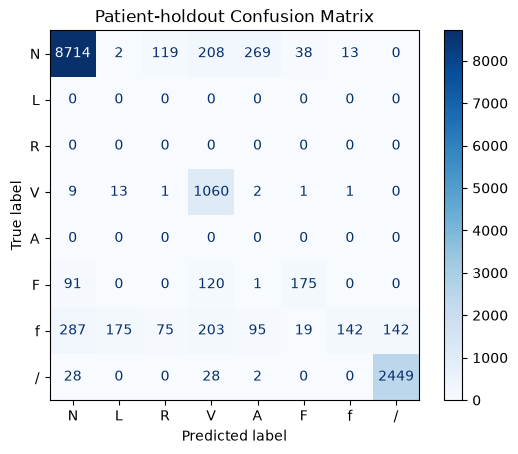

In [13]:
# Define evaluation function
def evaluate_model(y_test, y_pred):
    accuracy = accuracy_score(y_test, y_pred)

    # FIX: average only over the classes that occur in the test set. L, R and A are
    # absent for these 5 patients; without labels=... any wrong prediction of L/R/A
    # added a class with score 0 and pulled the macro average down.
    present = np.unique(y_test)

    precision = precision_score(
        y_test, y_pred,
        labels=present,
        average='macro',
        zero_division=0
    )

    recall = recall_score(
        y_test, y_pred,
        labels=present,
        average='macro',
        zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred,
        labels=present,
        average='macro',
        zero_division=0
    )

    print("Accuracy:", accuracy)
    print("Precision:", precision)
    print("Recall:", recall)
    print("F1-score:", f1)

    cm = confusion_matrix(
        y_test, y_pred,
        labels=[1, 2, 3, 4, 5, 6, 7, 8]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=['N', 'L', 'R', 'V', 'A', 'F', 'f', '/']
    )

    disp.plot(cmap='Blues')
    plt.title('Patient-holdout Confusion Matrix')
    plt.savefig('figures/task3_confusion_matrix.png', dpi=200, bbox_inches='tight')  # FIX: save figure
    plt.show()

    return accuracy, precision, recall, f1, cm


results = evaluate_model(y_test, y_pred)

# FIX: save the predictions so Task 5 can compare all models with the same plots
np.save('results/task3_svm_patients_pred.npy', y_pred)

**What to notice.** Accuracy falls from 0.938 to 0.866, and macro F1 from 0.82 to 0.69. Two beats from the
same patient look alike, so the beat hold-out score is optimistic (information *leaks* from training to
test). The patient hold-out is closer to how the model would do on a new patient. Most **f** beats
(fusion of paced and normal) of the unseen patients are missed.

## 4. Task 4: PermFIT on the two SVMs
*Code: `ecg_utils.py` (helpers) and `task4_permfit.py`.*

**Idea:** if the model needs a part of the heartbeat, destroying that part should make its predictions
worse. PermFIT measures *how much* worse, for 11 parts of the beat:

| slices | 25 samples each | ECG region |
|---|---|---|
| 1–4 | samples 0–99 | PR interval (P-wave) |
| 5–7 | samples 100–174 | QRS complex (R-peak in slice 6) |
| 8–11 | samples 175–274 | ST segment / T-wave |

### 4.1 The models and their probabilities

PermFIT compares the **predicted class probabilities** with the true label, so the model must output
probabilities. An SVM only outputs a class. **Platt scaling** (`CalibratedClassifierCV`) fits a small
logistic curve on top of the SVM's scores to turn them into probabilities. The decision boundary stays
the same SVM.

`make_model` builds exactly the SVMs of Tasks 2 and 3, and the Random Forest used in Task 5:

In [14]:
def make_model(name, split, probability=False):
    if name == "Random Forest":
        # settings from tune_hyperparameters.py
        return RandomForestClassifier(n_estimators=300, max_features=0.1, min_samples_leaf=1,
                                      n_jobs=-1, random_state=SEED)

    # same SVMs as task2_svm.py (beats) and task3.py (patients)
    if split == "beats":
        model = SVC(kernel="rbf")
    else:
        model = make_pipeline(StandardScaler(), SVC(max_iter=10000, random_state=SEED))

    # PermFIT needs class probabilities, so add Platt scaling on top of the SVM
    if probability:
        model = CalibratedClassifierCV(model, method="sigmoid", ensemble=False)
    return model

### 4.2 Destroying a slice

The handout asks to **shuffle the points inside the slice**. Three other ways are a sensitivity check: does
the answer depend on *how* the slice is destroyed?

In [15]:
def perturb_slice(X, j, mode, rng):
    # returns a copy of X where slice j (0-based) is destroyed
    s, e = j * SLICE_LENGTH, (j + 1) * SLICE_LENGTH
    Xp = X.copy()
    if mode == "shuffle":      # shuffle the points inside the slice (main method)
        Xp[:, s:e] = rng.permuted(X[:, s:e], axis=1)
    elif mode == "permute":    # take the slice from another random beat
        Xp[:, s:e] = X[rng.permutation(len(X)), s:e]
    elif mode == "zero":
        Xp[:, s:e] = 0.0
    elif mode == "mean":
        Xp[:, s:e] = X[:, s:e].mean(axis=1, keepdims=True)
    return Xp

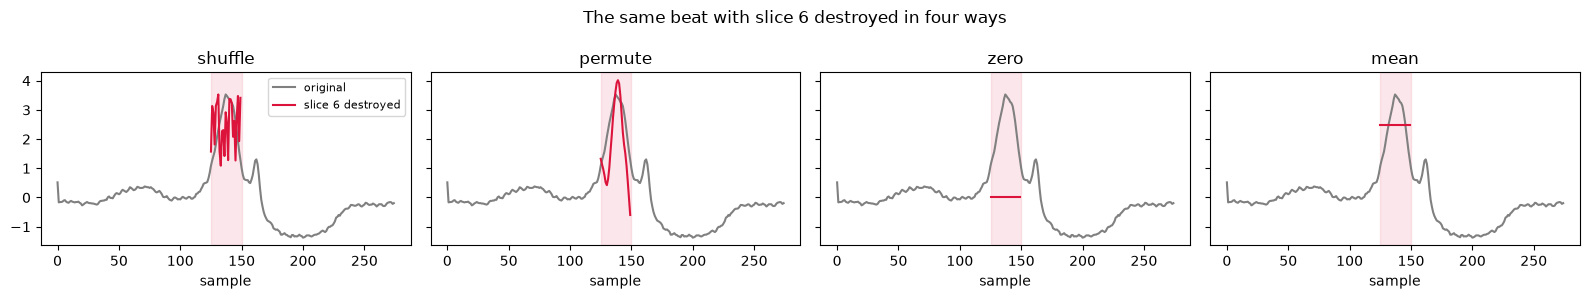

In [16]:
# Example: one V beat with slice 6 destroyed in each of the four ways
X_train, y_train, _, _ = load_split("beats")
i = np.flatnonzero(y_train == 4)[0]          # first V (premature ventricular) beat
j = 5                                        # slice 6 (0-based index 5)
rng = np.random.default_rng(0)
s, e = j * SLICE_LENGTH, (j + 1) * SLICE_LENGTH

fig, axes = plt.subplots(1, 4, figsize=(16, 3), sharey=True)
for ax, mode in zip(axes, ["shuffle", "permute", "zero", "mean"]):
    ax.plot(X_train[i], color="grey", label="original")
    ax.plot(np.arange(s, e), perturb_slice(X_train, j, mode, rng)[i, s:e], color="crimson", label="slice 6 destroyed")
    ax.axvspan(s, e, color="crimson", alpha=0.1)
    ax.set_title(mode)
    ax.set_xlabel("sample")
axes[0].legend(fontsize=8)
fig.suptitle("The same beat with slice 6 destroyed in four ways")
fig.tight_layout()

*Shuffle* keeps the values but loses their order. *Permute* puts in a realistic slice from another beat.
*Zero* and *mean* replace the slice with a flat line.

### 4.3 The PermFIT algorithm

1. Split the training beats into **K = 5 folds**, stratified so every fold has the same class mix.
2. For each fold *k*: train a fresh model on the other 4 folds.
3. For every beat *i* in fold *k* and every slice *j*: destroy slice *j* and compare the squared error
   between the one-hot label $Y_i$ and the predicted probabilities $p$, before and after:

$$M_{ij} = \sum_c \big(Y_{ic} - p_c(X_i^{(j)})\big)^2 \;-\; \sum_c \big(Y_{ic} - p_c(X_i)\big)^2$$

4. Average over all beats: $\bar M_j$ is the importance of slice *j*. Above 0 means the model got worse
   without the slice; about 0 means the model does not use it.

**Why cross-fitting?** Every beat is scored by a model that never saw it in training, so the importance
reflects what generalises, not what the model memorised.

*Example:* a V beat predicted with $p_V = 0.9$ has error $(1-0.9)^2 + 0.1^2 \approx 0.02$. If shuffling
slice 6 drops $p_V$ to 0.3 and moves the rest to N ($p_N = 0.7$), the error becomes $0.7^2 + 0.7^2 = 0.98$,
so $M_{i6} \approx 0.96$.

In [17]:
def one_hot(y, classes):
    return (y[:, None] == classes[None, :]).astype(float)


def compute_permfit_ecg(model, X, y, modes=("shuffle",), n_splits=5):
    """PermFIT: importance of each slice, with stratified K-fold cross-fitting."""
    folds = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=SEED)
    rng = np.random.default_rng(SEED)

    M = {m: np.zeros((len(X), N_SLICES)) for m in modes}          # importance of slice j for beat i
    per_fold = {m: np.zeros((n_splits, N_SLICES)) for m in modes}
    correct = {m: np.zeros((len(X), N_SLICES), dtype=bool) for m in modes}
    base_correct = np.zeros(len(X), dtype=bool)
    base_acc, base_err = [], []

    for k, (train, test) in enumerate(folds.split(X, y)):
        fold_model = clone(model).fit(X[train], y[train])
        classes = fold_model.classes_
        Y = one_hot(y[test], classes)

        # squared error on the intact beats
        p = fold_model.predict_proba(X[test])
        err = ((Y - p) ** 2).sum(axis=1)
        base_correct[test] = classes[p.argmax(1)] == y[test]
        base_acc.append(base_correct[test].mean())
        base_err.append(err.mean())
        print(f"  fold {k + 1}/{n_splits}: train {len(train)}, test {len(test)}, accuracy {base_acc[-1]:.3f}", flush=True)

        # destroy each slice: importance = error after - error before
        for m in modes:
            for j in range(N_SLICES):
                p_perm = fold_model.predict_proba(perturb_slice(X[test], j, m, rng))
                M[m][test, j] = ((Y - p_perm) ** 2).sum(axis=1) - err
                per_fold[m][k, j] = M[m][test, j].mean()
                correct[m][test, j] = classes[p_perm.argmax(1)] == y[test]

    results = {"baseline": {"accuracy": np.array(base_acc), "sq_error": np.array(base_err)}}
    for m in modes:
        results[m] = {"mean": M[m].mean(axis=0), "per_fold": per_fold[m], "M": M[m],
                      "acc_drop": 100 * (base_correct.mean() - correct[m].mean(axis=0))}
    return results

All four perturbation modes reuse the same 5 fitted models, so the extra modes only cost predictions.
`acc_drop` is a simpler second measure: how many percentage points of accuracy are lost per slice.

### 4.4 Plotting and running PermFIT

In [18]:
def plot_permfit_importance(importance, per_fold, title, ax):
    colors = {"PR interval": "royalblue", "QRS complex": "crimson", "ST segment / T-wave": "darkgreen"}
    for label, a, b in SLICE_REGIONS:
        ax.axvspan(a - 0.5, b + 0.5, color=colors[label], alpha=0.12, label=f"{label} (slices {a}-{b})")
    slices = np.arange(1, N_SLICES + 1)
    # error bars = spread of the importance over the folds
    ax.bar(slices, importance, yerr=per_fold.std(axis=0), capsize=3, color="navy", width=0.6, zorder=3)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xticks(slices)
    ax.set_xlabel("ECG slice (25 samples each; R-peak in slice 6)")
    ax.set_ylabel(r"mean importance $\bar{M}_j$")
    ax.set_title(title)
    ax.grid(axis="y", ls=":", alpha=0.6, zorder=0)

In [19]:
import time

# shuffle is the main method, the other three are a sensitivity check
MODES = ("shuffle", "permute", "zero", "mean")


def tag(model_name, split):
    return model_name.replace(" ", "_").lower() + "_" + split


def run_permfit(model_name, split):
    X, y, _, _ = load_split(split)
    print(f"\n[{model_name} | {SPLITS[split]}] PermFIT on {len(X)} training beats", flush=True)
    start = time.time()
    res = compute_permfit_ecg(make_model(model_name, split, probability=True), X, y, modes=MODES)
    print(f"  done in {(time.time() - start) / 60:.1f} min")

    arrays = {"baseline_accuracy": res["baseline"]["accuracy"], "baseline_sq_error": res["baseline"]["sq_error"]}
    for m in MODES:
        for key in ("mean", "per_fold", "acc_drop"):
            arrays[f"{m}_{key}"] = res[m][key]
    np.savez(RESULTS_DIR / f"permfit_{tag(model_name, split)}.npz", **arrays)

    fig, ax = plt.subplots(figsize=(9, 4.5))
    plot_permfit_importance(res["shuffle"]["mean"], res["shuffle"]["per_fold"],
                            f"PermFIT (shuffle within slice) - {model_name}, {SPLITS[split]}", ax)
    ax.legend(loc="upper left", fontsize=8)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"permfit_{tag(model_name, split)}.png", dpi=200)
    plt.close(fig)

    ranking = np.argsort(-res["shuffle"]["mean"]) + 1
    print(f"  slices ranked by importance (shuffle): {ranking.tolist()}")

PermFIT runs on the **training** beats of each protocol (the test sets stay untouched for Tasks 2/3).
Each SVM run fits 5 models and takes about 16 minutes, so by default the saved results are loaded.

beat hold-out: slices ranked [6, 7, 5, 1, 8, 4, 11, 3, 2, 9, 10], QRS share 98.2%, CV accuracy inside PermFIT 0.958
patient hold-out: slices ranked [6, 5, 7, 1, 4, 3, 11, 8, 2, 10, 9], QRS share 94.9%, CV accuracy inside PermFIT 0.977


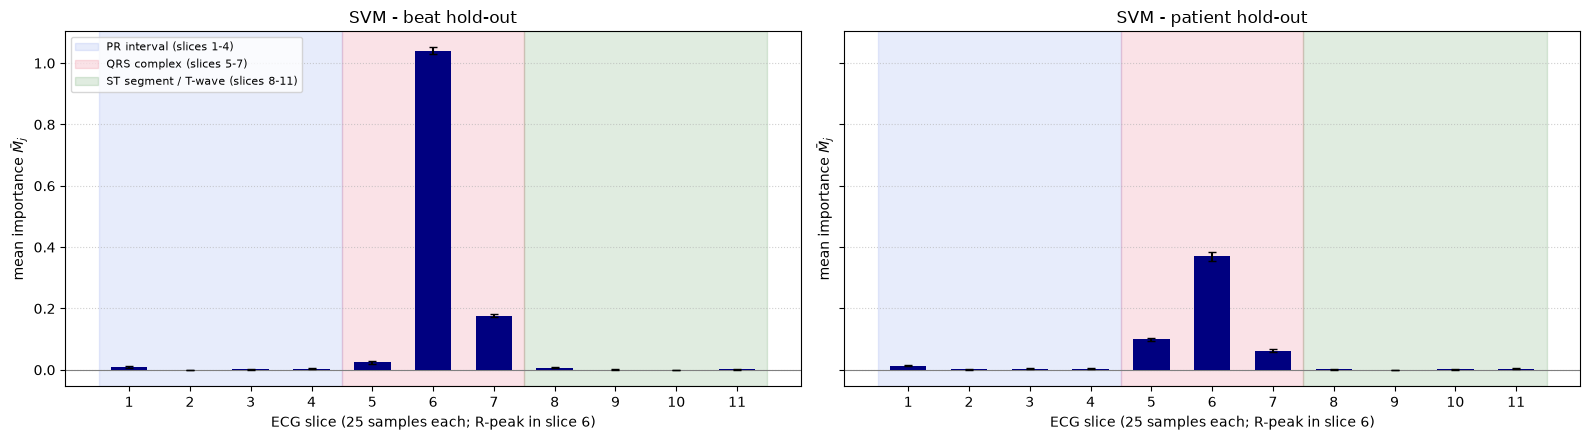

In [20]:
if RUN_PERMFIT:
    for split in SPLITS:
        run_permfit("SVM", split)


def qrs_share(mean_importance):
    # share of the total (positive) importance in the QRS slices 5-7 (notebook only)
    imp = np.clip(mean_importance, 0, None)
    return imp[4:7].sum() / imp.sum()


fig, axes = plt.subplots(1, 2, figsize=(16, 4.5), sharey=True)
for ax, (split, name) in zip(axes, SPLITS.items()):
    d = np.load(RESULTS_DIR / f"permfit_{tag('SVM', split)}.npz")
    plot_permfit_importance(d["shuffle_mean"], d["shuffle_per_fold"], title=f"SVM - {name}", ax=ax)
    print(f"{name}: slices ranked {(np.argsort(-d['shuffle_mean']) + 1).tolist()}, "
          f"QRS share {qrs_share(d['shuffle_mean']):.1%}, "
          f"CV accuracy inside PermFIT {d['baseline_accuracy'].mean():.3f}")
axes[0].legend(loc="upper left", fontsize=8)
fig.tight_layout()

**Reading the result.**
- Both SVMs rely almost only on the **QRS complex**, most of all on slice 6, which holds the R-peak. This
  fits cardiology: L, R, V and paced beats differ mainly in QRS shape and width.
- The error bars, which show the spread over the 5 folds, are small, so the ranking is stable.
- **Slice 1 ranks 4th.** It holds no useful ECG feature, but it contains sample 0: a padded zero that
  becomes a spike after standardisation. The SVM uses this preprocessing artefact, which explainability
  methods can reveal.
- The cross-validation accuracy inside PermFIT is 96–98%, but only 87% on new patients (Task 3). PermFIT
  explains what the model learned from the *training* patients.

## 5. Task 5: the same analysis with a Random Forest

A **Random Forest** is a vote of many decision trees. Each tree asks yes/no questions about single time
points ("is sample 140 above 1.2?"), while the SVM compares whole beats. If both models rely on the same
slices, the explanation is about the data, not one model.

### 5.1 Choosing the Random Forest settings
*Code: `tune_hyperparameters.py`.*

**Grid search**: try every combination of settings with 3-fold cross-validation on 8,000 training beats,
and keep the one with the best macro F1. The test sets are never used for tuning. Takes about a minute.

In [21]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.svm import SVC


X, y, _, _ = load_split("beats")
X_tune, _, y_tune, _ = train_test_split(X, y, train_size=8000, stratify=y, random_state=SEED)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

searches = {
    "SVM": GridSearchCV(SVC(kernel="rbf"), {"C": [1, 10, 100]}, cv=cv, scoring="f1_macro", n_jobs=-1),
    "Random Forest": GridSearchCV(RandomForestClassifier(n_estimators=200, random_state=SEED),
                                  {"max_features": ["sqrt", 0.1], "min_samples_leaf": [1, 3]},
                                  cv=cv, scoring="f1_macro", n_jobs=-1),
}

rows = []
for name, search in searches.items():
    search.fit(X_tune, y_tune)
    print(f"{name}: best {search.best_params_}  CV macro-F1 = {search.best_score_:.3f}")
    results = search.cv_results_
    for params, mean, std in zip(results["params"], results["mean_test_score"], results["std_test_score"]):
        rows.append({"model": name, "params": str(params), "cv_macro_f1": round(mean, 3), "std": round(std, 3)})

pd.DataFrame(rows).to_csv(RESULTS_DIR / "tuning_results.csv", index=False)
pd.DataFrame(rows)

SVM: best {'C': 100}  CV macro-F1 = 0.960


Random Forest: best {'max_features': 0.1, 'min_samples_leaf': 1}  CV macro-F1 = 0.954


,model,params,cv_macro_f1,std
0,SVM,{'C': 1},0.928,0.002
1,SVM,{'C': 10},0.955,0.003
2,SVM,{'C': 100},0.960,0.001
3,Random Forest,"{'max_features': 'sqrt', 'min_samples_leaf': 1}",0.954,0.001
4,Random Forest,"{'max_features': 'sqrt', 'min_samples_leaf': 3}",0.950,0.004
5,Random Forest,"{'max_features': 0.1, 'min_samples_leaf': 1}",0.954,0.001
6,Random Forest,"{'max_features': 0.1, 'min_samples_leaf': 3}",0.950,0.003


`max_features = 0.1` (each split tries 10% of the 275 time points) ties with `sqrt` and is used, with 300
trees. The SVM rows are for reference only: the SVMs keep the team's settings from Tasks 2 and 3 (C = 1),
so Task 4 explains exactly those models.

### 5.2 One evaluation function for all four models
*Code: `ecg_utils.py`.*

Tasks 2 and 3 used slightly different metric code, so all four models are re-scored with the same
function. Macro scores average only the classes present in the test set, and the confusion matrix is
normalised per row: each row shows where the beats of one true class went, so rare classes are as easy to
read as N.

In [22]:
def evaluate(y_true, y_pred, title, save_as):
    acc = accuracy_score(y_true, y_pred)
    p, r, f, support = precision_recall_fscore_support(y_true, y_pred, labels=CLASS_IDS, zero_division=0)

    # macro scores only use the classes that appear in the test set
    present = [c for c in CLASS_IDS if c in y_true]
    idx = [CLASS_IDS.index(c) for c in present]
    scores = {"model": title, "accuracy": acc, "macro_precision": p[idx].mean(),
              "macro_recall": r[idx].mean(), "macro_f1": f[idx].mean()}

    print(f"=== {title} ===")
    print(f"Accuracy: {acc:.4f}\n")
    print("class precision  recall     f1  support")
    for i, name in enumerate(CLASS_NAMES):
        note = "" if CLASS_IDS[i] in present else "   (not in test set)"
        print(f"{name:>5} {p[i]:9.3f} {r[i]:7.3f} {f[i]:6.3f} {support[i]:8d}{note}")
    print(f"\nMacro (classes present): precision={scores['macro_precision']:.3f} "
          f"recall={scores['macro_recall']:.3f} f1={scores['macro_f1']:.3f}\n")

    # confusion matrix with each row divided by the number of beats of that class
    cm = confusion_matrix(y_true, y_pred, labels=CLASS_IDS)
    cm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(6.5, 5.5))
    ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap="Blues", values_format=".2f", colorbar=False)
    ax.set_title(f"{title}\n(rows = true class, normalised)")
    fig.tight_layout()
    fig.savefig(FIG_DIR / save_as, dpi=200)
    return scores

### 5.3 Classification: SVM vs Random Forest
*Code: `task5_compare_classifiers.py`, step 1.*

The SVM predictions are the ones saved by the Task 2 and Task 3 cells above; the Random Forest is trained
here (under a minute).

=== SVM - beat hold-out ===
Accuracy: 0.9384

class precision  recall     f1  support
    N     0.996   0.927  0.960    28474
    L     0.983   0.994  0.989     1636
    R     0.996   0.992  0.994     2581
    V     0.715   0.940  0.812     1307
    A     0.519   0.893  0.656      783
    F     0.172   0.932  0.291      191
    f     0.730   0.950  0.825      416
    /     0.993   0.993  0.993     2054

Macro (classes present): precision=0.763 recall=0.953 f1=0.815



=== Random Forest - beat hold-out ===
Accuracy: 0.9677

class precision  recall     f1  support
    N     0.996   0.965  0.980    28474
    L     0.979   0.999  0.989     1636
    R     0.991   0.990  0.991     2581
    V     0.740   0.964  0.837     1307
    A     0.631   0.899  0.741      783
    F     0.607   0.890  0.722      191
    f     0.862   0.930  0.895      416
    /     0.990   0.994  0.992     2054

Macro (classes present): precision=0.850 recall=0.954 f1=0.893



=== SVM - patient hold-out ===
Accuracy: 0.8659

class precision  recall     f1  support
    N     0.955   0.931  0.942     9363
    L     0.000   0.000  0.000        0   (not in test set)
    R     0.000   0.000  0.000        0   (not in test set)
    V     0.655   0.975  0.783     1087
    A     0.000   0.000  0.000        0   (not in test set)
    F     0.751   0.452  0.565      387
    f     0.910   0.125  0.219     1138
    /     0.945   0.977  0.961     2507

Macro (classes present): precision=0.843 recall=0.692 f1=0.694



=== Random Forest - patient hold-out ===
Accuracy: 0.8356

class precision  recall     f1  support
    N     0.943   0.910  0.926     9363
    L     0.000   0.000  0.000        0   (not in test set)
    R     0.000   0.000  0.000        0   (not in test set)
    V     0.626   0.990  0.767     1087
    A     0.000   0.000  0.000        0   (not in test set)
    F     0.500   0.003  0.005      387
    f     1.000   0.004  0.007     1138
    /     0.888   0.998  0.940     2507

Macro (classes present): precision=0.791 recall=0.581 f1=0.529

        model         protocol  accuracy  macro_precision  macro_recall  macro_f1
          SVM    beat hold-out     0.938            0.763         0.953     0.815
          SVM patient hold-out     0.866            0.843         0.692     0.694
Random Forest    beat hold-out     0.968            0.850         0.954     0.893
Random Forest patient hold-out     0.836            0.791         0.581     0.529


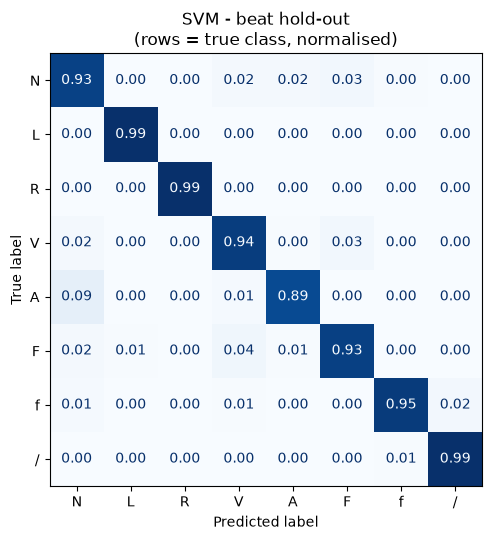

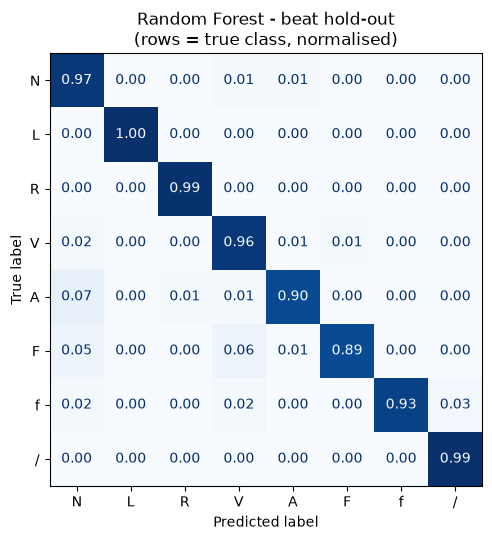

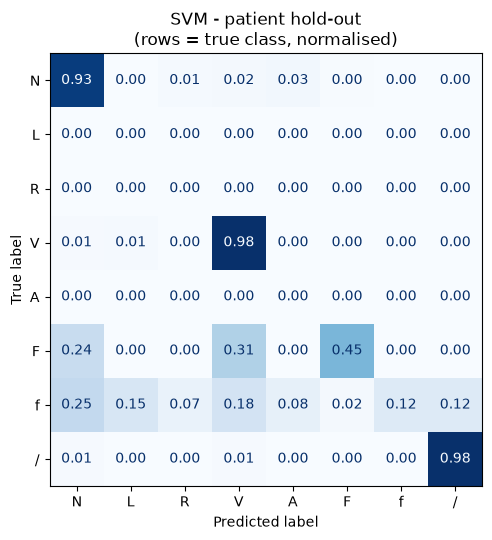

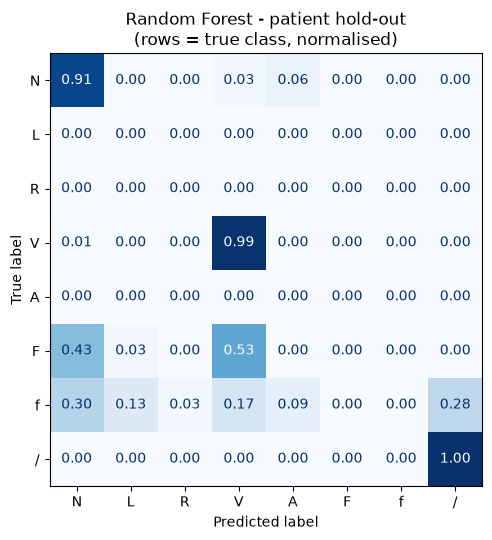

In [23]:
import json

MODELS = ["SVM", "Random Forest"]
SVM_PREDICTIONS = {"beats": "task2_svm_beats_pred.npy", "patients": "task3_svm_patients_pred.npy"}

# 1. Classification: score the saved SVM predictions and train the Random Forest
for split, split_name in SPLITS.items():
    X_train, y_train, X_test, y_test = load_split(split)

    svm_pred = np.load(RESULTS_DIR / SVM_PREDICTIONS[split])
    res = evaluate(y_test, svm_pred, f"SVM - {split_name}", f"cm_svm_{split}.png")
    (RESULTS_DIR / f"metrics_svm_{split}.json").write_text(json.dumps(res, indent=2))

    rf = make_model("Random Forest", split).fit(X_train, y_train)
    res = evaluate(y_test, rf.predict(X_test), f"Random Forest - {split_name}", f"cm_random_forest_{split}.png")
    (RESULTS_DIR / f"metrics_random_forest_{split}.json").write_text(json.dumps(res, indent=2))

rows = []
for model in MODELS:
    for split, split_name in SPLITS.items():
        m = json.loads((RESULTS_DIR / f"metrics_{tag(model, split)}.json").read_text())
        rows.append({"model": model, "protocol": split_name, "accuracy": m["accuracy"],
                     "macro_precision": m["macro_precision"], "macro_recall": m["macro_recall"],
                     "macro_f1": m["macro_f1"]})
table = pd.DataFrame(rows).round(3)
table.to_csv(RESULTS_DIR / "classification_summary.csv", index=False)
print(table.to_string(index=False))

The Random Forest wins on the beat hold-out (macro F1 0.89 vs 0.82) but loses on new patients (0.53 vs
0.69): it misses almost all F and f beats of the unseen patients. It fits the training patients more
closely, which helps when the same patients are in the test set and hurts when they are not.

### 5.4 PermFIT on the Random Forest
*Code: `task5_compare_classifiers.py`, step 2: the same `run_permfit` with the same settings as Task 4.*

In [24]:
# 2. PermFIT on the Random Forest
if RUN_PERMFIT:
    for split in SPLITS:
        run_permfit("Random Forest", split)

pf = {}
for model in MODELS:
    for split in SPLITS:
        pf[model, split] = np.load(RESULTS_DIR / f"permfit_{tag(model, split)}.npz")

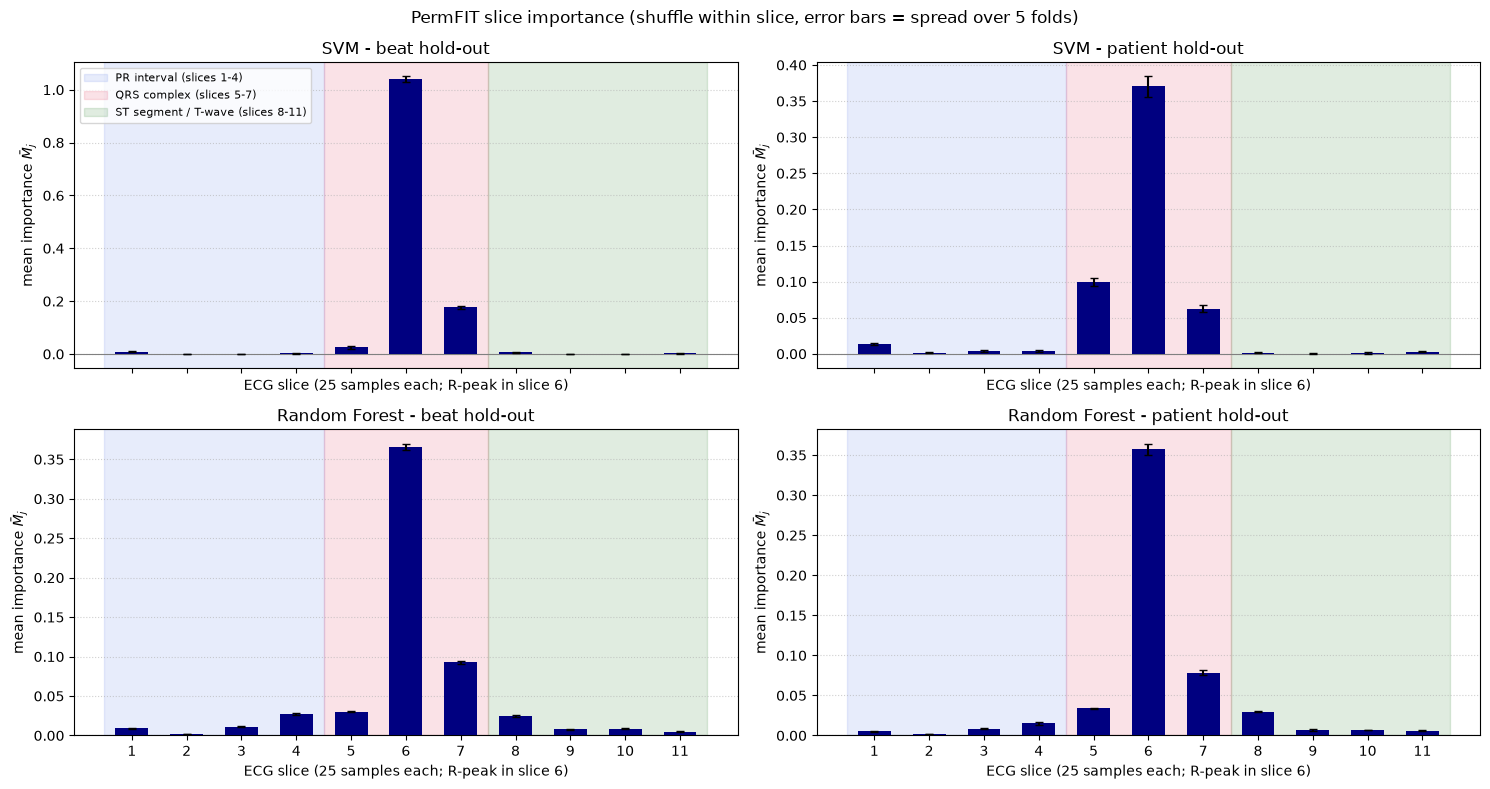

In [25]:
# 3. Importance of every slice for all four models
fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=True)
for r, model in enumerate(MODELS):
    for c, (split, split_name) in enumerate(SPLITS.items()):
        d = pf[model, split]
        plot_permfit_importance(d["shuffle_mean"], d["shuffle_per_fold"], f"{model} - {split_name}", axes[r, c])
axes[0, 0].legend(loc="upper left", fontsize=8)
fig.suptitle("PermFIT slice importance (shuffle within slice, error bars = spread over 5 folds)")
fig.tight_layout()
fig.savefig(FIG_DIR / "permfit_comparison_grid.png", dpi=200)

The models' raw scores are on different scales (a confident model loses more when it is wrong), so the
next plot normalises each model's importances to 100% to compare *where* they look.

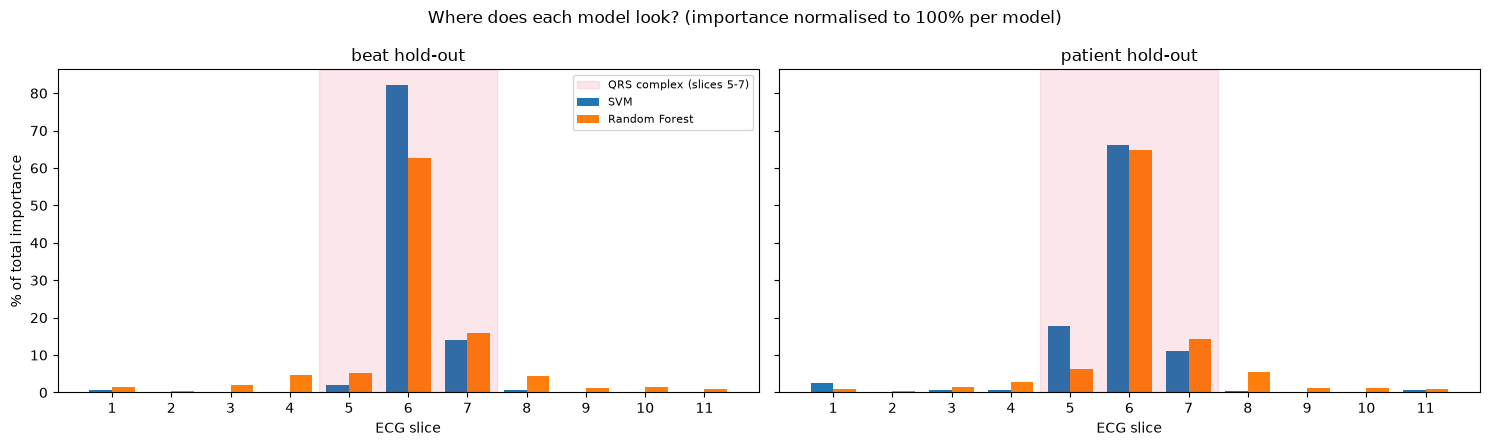

In [26]:
# 4. Same importances as % of each model's total, to compare where the models look
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
width = 0.38
for ax, (split, split_name) in zip(axes, SPLITS.items()):
    for k, model in enumerate(MODELS):
        imp = np.clip(pf[model, split]["shuffle_mean"], 0, None)
        ax.bar(np.arange(1, 12) + (k - 0.5) * width, 100 * imp / imp.sum(), width, label=model)
    for label, a, b in SLICE_REGIONS:
        if label == "QRS complex":
            ax.axvspan(a - 0.5, b + 0.5, color="crimson", alpha=0.1, label="QRS complex (slices 5-7)")
    ax.set_xticks(np.arange(1, 12))
    ax.set_xlabel("ECG slice")
    ax.set_title(split_name)
axes[0].set_ylabel("% of total importance")
axes[0].legend(fontsize=8)
fig.suptitle("Where does each model look? (importance normalised to 100% per model)")
fig.tight_layout()
fig.savefig(FIG_DIR / "permfit_profiles_svm_vs_rf.png", dpi=200)

Both models look mostly at the QRS complex. The Random Forest spreads its attention more: it also uses
slices 4 and 8, the start and end of the QRS complex, while the SVM concentrates on slice 6.

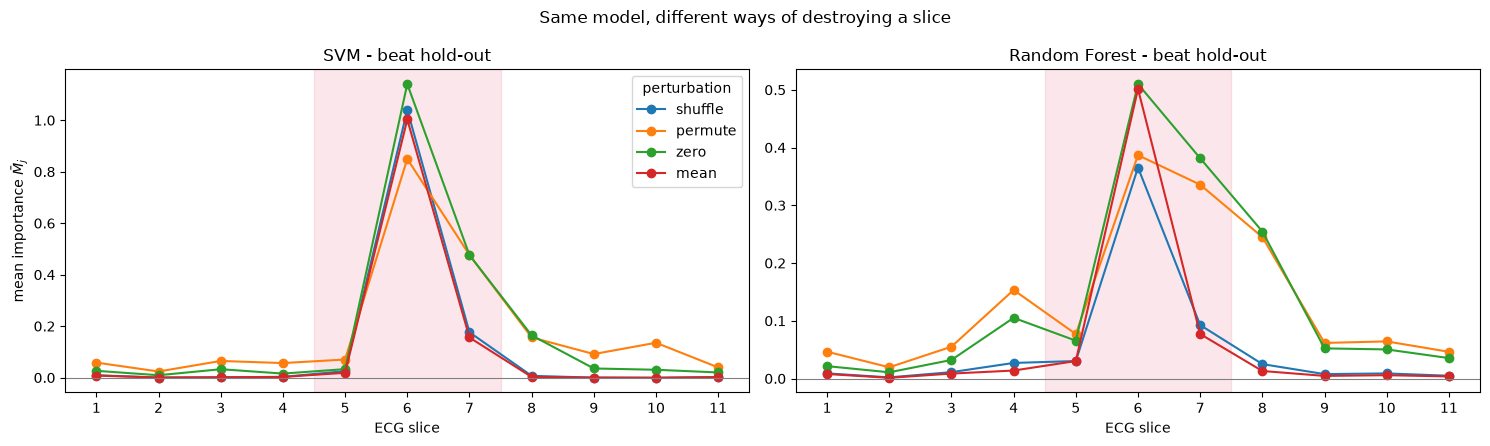

In [27]:
# 5. Does the result depend on how the slice is destroyed? (beat hold-out)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, model in zip(axes, MODELS):
    for mode in MODES:
        ax.plot(np.arange(1, 12), pf[model, "beats"][f"{mode}_mean"], marker="o", label=mode)
    ax.axvspan(4.5, 7.5, color="crimson", alpha=0.1)
    ax.axhline(0, color="grey", lw=0.8)
    ax.set_xticks(np.arange(1, 12))
    ax.set_xlabel("ECG slice")
    ax.set_title(f"{model} - beat hold-out")
axes[0].set_ylabel(r"mean importance $\bar{M}_j$")
axes[0].legend(title="perturbation")
fig.suptitle("Same model, different ways of destroying a slice")
fig.tight_layout()
fig.savefig(FIG_DIR / "permfit_perturbation_methods.png", dpi=200)

The *size* of the importance depends on how a slice is destroyed: zero and permute also show some
importance in the ST segment and T-wave. The *top* slice is the same in all 16 runs (2 models ×
2 protocols × 4 methods): slice 6.

### 5.5 Tables for the report

In [28]:
# 6. Tables for the report
long = []
for (model, split), d in pf.items():
    for mode in MODES:
        for j in range(11):
            long.append({"model": model, "protocol": SPLITS[split], "perturbation": mode, "slice": j + 1,
                         "importance": d[f"{mode}_mean"][j], "fold_std": d[f"{mode}_per_fold"][:, j].std(),
                         "accuracy_drop_pct": d[f"{mode}_acc_drop"][j]})
long = pd.DataFrame(long)
long.to_csv(RESULTS_DIR / "permfit_all_results.csv", index=False)

main = long[long.perturbation == "shuffle"].pivot_table(index="slice", columns=["model", "protocol"], values="importance")
main = main.round(4)
main.to_csv(RESULTS_DIR / "permfit_shuffle_table.csv")
print(main.to_string())

model    Random Forest                            SVM                 
protocol beat hold-out patient hold-out beat hold-out patient hold-out
slice                                                                 
1               0.0089           0.0052        0.0093           0.0137
2               0.0020           0.0023        0.0003           0.0014
3               0.0111           0.0085        0.0012           0.0035
4               0.0270           0.0153        0.0030           0.0039
5               0.0303           0.0339        0.0250           0.0990
6               0.3654           0.3572        1.0402           0.3703
7               0.0926           0.0786        0.1762           0.0627
8               0.0250           0.0298        0.0069           0.0016
9               0.0077           0.0068       -0.0001          -0.0001
10              0.0089           0.0070       -0.0007           0.0011
11              0.0048           0.0058        0.0022           0.0032


In [29]:
# QRS share and top-3 slices per model (notebook only)
pd.DataFrame([{"model": model, "protocol": SPLITS[split],
               "QRS share (slices 5-7)": f"{qrs_share(d['shuffle_mean']):.1%}",
               "top-3 slices": (np.argsort(-d["shuffle_mean"])[:3] + 1).tolist(),
               "CV accuracy inside PermFIT": round(d["baseline_accuracy"].mean(), 3)}
              for (model, split), d in pf.items()])

,model,protocol,QRS share (slices 5-7),top-3 slices,CV accuracy inside PermFIT
0,SVM,beat hold-out,98.2%,"[6, 7, 5]",0.958
1,SVM,patient hold-out,94.9%,"[6, 5, 7]",0.977
2,Random Forest,beat hold-out,83.7%,"[6, 7, 5]",0.983
3,Random Forest,patient hold-out,85.3%,"[6, 7, 5]",0.986


## Summary

- **Classification:** the SVM generalises better to new patients (accuracy 0.866 vs 0.836 for the
  Random Forest). The beat hold-out overestimates performance for both models.
- **Explanation:** both models base their decisions on the QRS complex, mainly the R-peak (slice 6). The
  SVM is more concentrated (95–98% of importance in QRS) than the Random Forest (84–85%).
- **Caveats:** the SVM also uses the sample-0 artefact in slice 1, and the size of the importance depends
  on the perturbation method.

The full discussion is in `Report.pdf`.